<a href="https://colab.research.google.com/github/Mugunth8365/Data-Science-Journey-/blob/main/Day6%20review%20day%20of%20data%20science%20journey.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [102]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("penguins")
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
None
Empty DataFrame
Columns: [species, island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, sex]
Index: []


(344, 7)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
8    Adelie  Torgersen            34.1           18.1              193.0   
9    Adelie  Torgersen            42.0           20.2              190.0   
10   Adelie  Torgersen            37.8           17.1              186.0   
11   Adelie  Torgersen            37.8           17.3              180.0   
47   Adelie      Dream            37.5           18.9              179.0   
246  Gentoo     Biscoe            44.5           14.3              216.0   
286  Gentoo     Biscoe            46.2           14.4              214.0   
324  Gentoo     Biscoe            47.3           13.8              216.0   
336  Gentoo     Biscoe            44.5           1

/tmp/ipykernel_948/2478614030.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean["is_heavy"]=clean["body_mass_g"]>4500


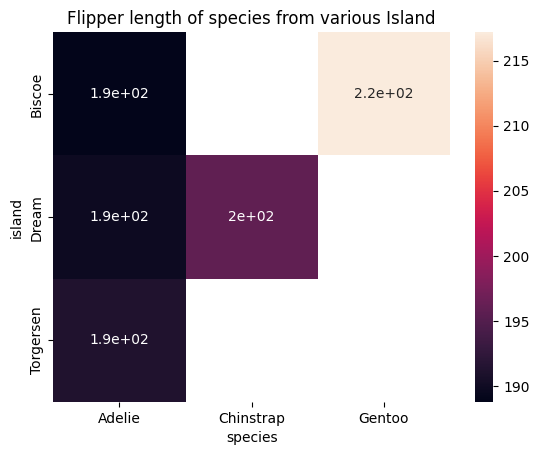

The species with the longest average bill length is Chinstrap with 48.8mm length
The heaviest species on average is Gentoo with the average of 5076.0g and it is hevier than the lightest species by 1375.4g
68
<bound method IndexOpsMixin.value_counts of 151    Chinstrap
152    Chinstrap
153    Chinstrap
154    Chinstrap
155    Chinstrap
         ...    
214    Chinstrap
215    Chinstrap
216    Chinstrap
217    Chinstrap
218    Chinstrap
Name: species, Length: 68, dtype: object>


In [103]:
print(df.shape)
print(df.isna().sum())

print(df[df["sex"].isna()])
print(df["sex"].isna().sum())

print(df.shape)
clean=df[df["body_mass_g"].notna()]
print(clean.shape)

clean["is_heavy"]=clean["body_mass_g"]>4500
print(clean["is_heavy"].sum(),"\n",clean["is_heavy"].mean()*100)

print(clean.groupby("species")["body_mass_g"].aggregate(["count","mean"]))

pivot_table=clean.pivot_table(values="flipper_length_mm",index="island",columns="species",aggfunc="mean")
print(pivot_table)
sns.heatmap(pivot_table,annot=True)
plt.title("Flipper length of species from various Island")
plt.show()

average_bill=df.groupby("species")["bill_length_mm"].mean()
print(f"The species with the longest average bill length is {average_bill.idxmax()} with {average_bill.max():.1f}mm length")

average_weight=df.groupby("species")["body_mass_g"].mean()
print(f"The heaviest species on average is {average_weight.idxmax()} with the average of {average_weight.max():.1f}g and it is hevier than the lightest species by {(average_weight.max()- average_weight.min()):.1f}g")

info = pd.DataFrame({
    "species": ["Adelie", "Gentoo"],
    "scientific_name": ["Pygoscelis adeliae", "Pygoscelis papua"]
})
clean=clean.merge(info,on="species",how="left")
print(clean["scientific_name"].isna().sum())
print(clean[clean["scientific_name"].isna()]["species"].value_counts)